# Notebook 06 - Eksperimen Tambahan pada Dataset noDDS

**Tahap penelitian:** Analisis kandidat eksperimen tambahan.

Notebook ini memuat analisis rinci eksperimen tambahan pada noDDS 164 fitur. Untuk menjalankan grid yang sama pada kedua varian DDS dan noDDS secara berpasangan, gunakan `scripts/run_paired_experiments.py`; hasil validasi dan test kandidat terpilih ditampilkan di Notebook 08. Pemilihan kandidat memakai validation saja.


## 0. Setup


In [20]:
import sys
import json
import time
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

_root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _root_candidates if (p / "configs" / "config.yaml").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root repo (configs/config.yaml dan src/). Jalankan notebook dari repo atau folder notebooks.")
sys.path.insert(0, str(ROOT))

OUT       = ROOT / 'outputs' / 'results'
MODEL_DIR = ROOT / 'outputs' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
sns.set_palette('tab10')
print('Setup selesai.')


Setup selesai.


## 1. Load Dataset & Baseline


In [21]:
from src.preprocessing import load_splits
from src.evaluation import evaluate, print_summary

df_train, df_val, df_test, feature_cols, le = load_splits(ROOT / 'data' / 'processed_no_dds')

X_train = df_train[feature_cols].values.astype(np.float32)
y_train = df_train['label'].values
X_val   = df_val[feature_cols].values.astype(np.float32)
y_val   = df_val['label'].values

n_classes  = len(le.classes_)
n_features = len(feature_cols)

print(f'Train  : {X_train.shape}  (matches_par_contract=1 rate: {y_train.mean():.1%})')
print(f'Val    : {X_val.shape}')
print(f'Kelas  : {n_classes}')
print(f'Fitur  : {n_features}')


Train  : (35161, 164)  (matches_par_contract=1 rate: 24.6%)
Val    : (7534, 164)
Kelas  : 2
Fitur  : 164


In [22]:
# Muat model resmi (baseline saat ini) untuk jadi titik pembanding
with open(MODEL_DIR / 'xgboost.pkl', 'rb') as f:
    xgb_baseline = pickle.load(f)
with open(MODEL_DIR / 'lightgbm.pkl', 'rb') as f:
    lgbm_baseline = pickle.load(f)
with open(MODEL_DIR / 'randomforest.pkl', 'rb') as f:
    rf_baseline = pickle.load(f)

baseline_results = {}
for m in [rf_baseline, xgb_baseline, lgbm_baseline]:
    y_pred  = m.predict(X_val)
    y_proba = m.predict_proba(X_val)
    res = evaluate(y_val, y_pred, y_proba, le, model_name=m.name)
    baseline_results[m.name] = res
    print_summary(res)



  RandomForest
  Accuracy          : 0.7653
  Precision (macro) : 0.6711
  Recall (macro)    : 0.6170
  F1 (macro)        : 0.6295
  F1 (weighted)     : 0.7436
  F1 (positive)     : 0.4051
  ROC-AUC           : 0.7148
  PR-AUC (avg prec) : 0.4704

  XGBoost
  Accuracy          : 0.7712
  Precision (macro) : 0.6994
  Recall (macro)    : 0.5729
  F1 (macro)        : 0.5731
  F1 (weighted)     : 0.7210
  F1 (positive)     : 0.2823
  ROC-AUC           : 0.7115
  PR-AUC (avg prec) : 0.4665

  LightGBM
  Accuracy          : 0.7213
  Precision (macro) : 0.6373
  Recall (macro)    : 0.6509
  F1 (macro)        : 0.6425
  F1 (weighted)     : 0.7279
  F1 (positive)     : 0.4747
  ROC-AUC           : 0.7126
  PR-AUC (avg prec) : 0.4590


## 2. Eksperimen A - Grid XGBoost berdasarkan AP validation

Grid kecil membandingkan konfigurasi XGBoost, termasuk konfigurasi `config.yaml`. Setiap kandidat dilatih pada train dan dibandingkan pada validation. Kandidat terbaik di dalam eksperimen dipilih berdasarkan AP validation; metrik lain dilaporkan sebagai pendamping. Hasil lama tidak dianggap sebagai hasil final noDDS.


In [23]:
from xgboost import XGBClassifier

xgb_param_grid = {
    'default (config.yaml)': dict(n_estimators=300, max_depth=6, learning_rate=0.05,
                                   subsample=0.8, colsample_bytree=0.8),
    'deeper_more_trees':     dict(n_estimators=500, max_depth=8, learning_rate=0.05,
                                   subsample=0.9, colsample_bytree=0.8,
                                   min_child_weight=1, reg_lambda=1.0),
    'mid_capacity':          dict(n_estimators=400, max_depth=7, learning_rate=0.08,
                                   subsample=0.85, colsample_bytree=0.7,
                                   min_child_weight=3, reg_lambda=1.5),
    'leaner_faster':         dict(n_estimators=250, max_depth=6, learning_rate=0.1,
                                   subsample=0.8, colsample_bytree=0.8),
}

xgb_grid_results = {}
for cand_name, params in xgb_param_grid.items():
    t0 = time.time()
    clf = XGBClassifier(**params, random_state=42, n_jobs=-1, verbosity=0, eval_metric='logloss')
    clf.fit(X_train, y_train)
    elapsed = time.time() - t0
    y_pred  = clf.predict(X_val)
    y_proba = clf.predict_proba(X_val)
    res = evaluate(y_val, y_pred, y_proba, le, model_name=f'XGBoost ({cand_name})')
    xgb_grid_results[cand_name] = {'clf': clf, 'params': params, 'res': res, 'elapsed': elapsed}
    print(f'[{cand_name:<22}] {elapsed:>6.0f}s  acc={res["accuracy"]:.4f}  f1_macro={res["f1_macro"]:.4f}')

best_xgb_name   = max(xgb_grid_results, key=lambda k: xgb_grid_results[k]['res']['average_precision'])
best_xgb_params = xgb_grid_results[best_xgb_name]['params']
print(f'\nKandidat terbaik (AP validation): {best_xgb_name} -> {best_xgb_params}')


[default (config.yaml) ]      5s  acc=0.7712  f1_macro=0.5731
[deeper_more_trees     ]      9s  acc=0.7679  f1_macro=0.5739
[mid_capacity          ]      7s  acc=0.7669  f1_macro=0.5754
[leaner_faster         ]      4s  acc=0.7704  f1_macro=0.5820

Kandidat terbaik (AP validation): default (config.yaml) -> {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}


In [24]:
xgb_a = xgb_grid_results[best_xgb_name]['clf']
res_a = xgb_grid_results[best_xgb_name]['res']
res_a['model'] = 'XGBoost (Exp A: retuned)'
y_proba_a = xgb_a.predict_proba(X_val)
print_summary(res_a)

# baseline XGBoost sekarang juga memakai default config.yaml, jadi Exp A
# pada dasarnya mengonfirmasi ulang baseline (bukan lagi "mengalahkan acc-tuned").
print(f'\nExp A vs baseline XGBoost (keduanya default config.yaml):')
print(f'  Accuracy : baseline {baseline_results["XGBoost"]["accuracy"]:.4f}  |  Exp A {res_a["accuracy"]:.4f}')
print(f'  F1 Macro : baseline {baseline_results["XGBoost"]["f1_macro"]:.4f}  |  Exp A {res_a["f1_macro"]:.4f}')
print(f'  Kandidat grid terpilih: {best_xgb_name}')



  XGBoost (Exp A: retuned)
  Accuracy          : 0.7712
  Precision (macro) : 0.6994
  Recall (macro)    : 0.5729
  F1 (macro)        : 0.5731
  F1 (weighted)     : 0.7210
  F1 (positive)     : 0.2823
  ROC-AUC           : 0.7115
  PR-AUC (avg prec) : 0.4665

Exp A vs baseline XGBoost (keduanya default config.yaml):
  Accuracy : baseline 0.7712  |  Exp A 0.7712
  F1 Macro : baseline 0.5731  |  Exp A 0.5731
  Kandidat grid terpilih: default (config.yaml)


## 3. Eksperimen B — XGBoost (params Eksperimen A) + sample_weight seimbang kelas PENUH

XGBoost tidak memiliki `class_weight="balanced"` native seperti sklearn/LightGBM. Eksperimen ini memakai `sample_weight` per baris dari `compute_sample_weight('balanced', y_train)` dan membandingkan hasilnya terhadap kandidat tanpa bobot pada validation.


In [25]:
from sklearn.utils.class_weight import compute_sample_weight

sw_balanced = compute_sample_weight('balanced', y_train)

xgb_b = XGBClassifier(
    **best_xgb_params, random_state=42, n_jobs=-1, verbosity=0, eval_metric='logloss',
)
xgb_b.fit(X_train, y_train, sample_weight=sw_balanced)

y_pred_b  = xgb_b.predict(X_val)
y_proba_b = xgb_b.predict_proba(X_val)
res_b = evaluate(y_val, y_pred_b, y_proba_b, le, model_name='XGBoost (Exp B: retuned+balanced)')
print_summary(res_b)

print(f'\nDibanding Eksperimen A (tanpa sample_weight):')
print(f'  Accuracy : {res_a["accuracy"]:.4f} -> {res_b["accuracy"]:.4f}'
      f'  ({(res_b["accuracy"]-res_a["accuracy"])*100:+.2f}pp)')
print(f'  F1 Macro : {res_a["f1_macro"]:.4f} -> {res_b["f1_macro"]:.4f}'
      f'  ({(res_b["f1_macro"]-res_a["f1_macro"])*100:+.2f}pp)')



  XGBoost (Exp B: retuned+balanced)
  Accuracy          : 0.7084
  Precision (macro) : 0.6330
  Recall (macro)    : 0.6553
  F1 (macro)        : 0.6393
  F1 (weighted)     : 0.7196
  F1 (positive)     : 0.4815
  ROC-AUC           : 0.7113
  PR-AUC (avg prec) : 0.4611

Dibanding Eksperimen A (tanpa sample_weight):
  Accuracy : 0.7712 -> 0.7084  (-6.28pp)
  F1 Macro : 0.5731 -> 0.6393  (+6.62pp)


## 4. Eksperimen C - Retuning LightGBM

Grid ini membandingkan konfigurasi LightGBM sambil mempertahankan `class_weight="balanced"`. Kandidat terbaik dipilih berdasarkan AP validation.


In [26]:
from lightgbm import LGBMClassifier

lgbm_param_grid = {
    'default (config.yaml)': dict(n_estimators=300, num_leaves=63, learning_rate=0.05,
                                   subsample=0.8, colsample_bytree=0.8),
    'more_leaves':           dict(n_estimators=400, num_leaves=95, learning_rate=0.05,
                                   subsample=0.8, colsample_bytree=0.8),
    'lower_lr_more_trees':   dict(n_estimators=500, num_leaves=63, learning_rate=0.03,
                                   subsample=0.85, colsample_bytree=0.7),
    'deep_constrained':      dict(n_estimators=350, num_leaves=127, max_depth=9,
                                   learning_rate=0.05, subsample=0.8, colsample_bytree=0.8),
}

lgbm_grid_results = {}
for cand_name, params in lgbm_param_grid.items():
    t0 = time.time()
    clf = LGBMClassifier(**params, random_state=42, n_jobs=-1, verbose=-1, class_weight='balanced')
    clf.fit(X_train, y_train)
    elapsed = time.time() - t0
    y_pred  = clf.predict(X_val)
    y_proba = clf.predict_proba(X_val)
    res = evaluate(y_val, y_pred, y_proba, le, model_name=f'LightGBM ({cand_name})')
    lgbm_grid_results[cand_name] = {'clf': clf, 'params': params, 'res': res, 'elapsed': elapsed}
    print(f'[{cand_name:<22}] {elapsed:>6.0f}s  acc={res["accuracy"]:.4f}  f1_macro={res["f1_macro"]:.4f}')

# Dipilih berdasarkan average_precision validation agar konsisten dengan metrik seleksi utama.
best_lgbm_name   = max(lgbm_grid_results, key=lambda k: lgbm_grid_results[k]['res']['average_precision'])
best_lgbm_params = lgbm_grid_results[best_lgbm_name]['params']
print(f'\nKandidat terbaik (AP validation): {best_lgbm_name} -> {best_lgbm_params}')


[default (config.yaml) ]      3s  acc=0.7213  f1_macro=0.6425
[more_leaves           ]      6s  acc=0.7394  f1_macro=0.6405
[lower_lr_more_trees   ]      5s  acc=0.7227  f1_macro=0.6470
[deep_constrained      ]      4s  acc=0.7335  f1_macro=0.6425

Kandidat terbaik (AP validation): deep_constrained -> {'n_estimators': 350, 'num_leaves': 127, 'max_depth': 9, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}


In [27]:
lgbm_c = lgbm_grid_results[best_lgbm_name]['clf']
res_c = lgbm_grid_results[best_lgbm_name]['res']
res_c['model'] = 'LightGBM (Exp C: retuned+balanced)'
y_proba_c = lgbm_c.predict_proba(X_val)
print_summary(res_c)

print(f'\nDibanding baseline LightGBM class_weight (config.yaml default hyperparameter):')
print(f'  Accuracy : {baseline_results["LightGBM"]["accuracy"]:.4f} -> {res_c["accuracy"]:.4f}'
      f'  ({(res_c["accuracy"]-baseline_results["LightGBM"]["accuracy"])*100:+.2f}pp)')
print(f'  F1 Macro : {baseline_results["LightGBM"]["f1_macro"]:.4f} -> {res_c["f1_macro"]:.4f}'
      f'  ({(res_c["f1_macro"]-baseline_results["LightGBM"]["f1_macro"])*100:+.2f}pp)')



  LightGBM (Exp C: retuned+balanced)
  Accuracy          : 0.7335
  Precision (macro) : 0.6417
  Recall (macro)    : 0.6434
  F1 (macro)        : 0.6425
  F1 (weighted)     : 0.7342
  F1 (positive)     : 0.4622
  ROC-AUC           : 0.7126
  PR-AUC (avg prec) : 0.4632

Dibanding baseline LightGBM class_weight (config.yaml default hyperparameter):
  Accuracy : 0.7213 -> 0.7335  (+1.22pp)
  F1 Macro : 0.6425 -> 0.6425  (+0.00pp)


## 5. Eksperimen E - Retuning Random Forest

Grid ini membandingkan konfigurasi Random Forest dengan baseline. Kandidat terbaik dipilih berdasarkan AP validation.


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'default (config.yaml)': dict(n_estimators=300, max_depth=None, min_samples_split=5),
    'more_trees':            dict(n_estimators=600, max_depth=None, min_samples_split=5),
    'regularized_shallow':   dict(n_estimators=400, max_depth=25, min_samples_split=10,
                                   min_samples_leaf=4),
    'more_features':         dict(n_estimators=400, max_depth=None, min_samples_split=5,
                                   max_features=0.5),
}

rf_grid_results = {}
for cand_name, params in rf_param_grid.items():
    t0 = time.time()
    clf = RandomForestClassifier(**params, class_weight='balanced', random_state=42, n_jobs=-1)
    clf.fit(X_train, y_train)
    elapsed = time.time() - t0
    y_pred  = clf.predict(X_val)
    y_proba = clf.predict_proba(X_val)
    res = evaluate(y_val, y_pred, y_proba, le, model_name=f'RandomForest ({cand_name})')
    rf_grid_results[cand_name] = {'clf': clf, 'params': params, 'res': res, 'elapsed': elapsed}
    print(f'[{cand_name:<22}] {elapsed:>6.0f}s  acc={res["accuracy"]:.4f}  f1_macro={res["f1_macro"]:.4f}')

best_rf_name   = max(rf_grid_results, key=lambda k: rf_grid_results[k]['res']['average_precision'])
best_rf_params = rf_grid_results[best_rf_name]['params']
print(f'\nKandidat terbaik (AP validation): {best_rf_name} -> {best_rf_params}')


[default (config.yaml) ]     12s  acc=0.7653  f1_macro=0.6295
[more_trees            ]     22s  acc=0.7664  f1_macro=0.6323
[regularized_shallow   ]     16s  acc=0.7441  f1_macro=0.6441
[more_features         ]     82s  acc=0.7655  f1_macro=0.6428

Kandidat terbaik (AP validation): more_trees -> {'n_estimators': 600, 'max_depth': None, 'min_samples_split': 5}


In [29]:
rf_e = rf_grid_results[best_rf_name]['clf']
res_e = rf_grid_results[best_rf_name]['res']
res_e['model'] = 'RandomForest (Exp E: retuned)'
y_proba_e = rf_e.predict_proba(X_val)
print_summary(res_e)

print(f'\nDibanding baseline RandomForest (config.yaml):')
print(f'  Accuracy : {baseline_results["RandomForest"]["accuracy"]:.4f} -> {res_e["accuracy"]:.4f}'
      f'  ({(res_e["accuracy"]-baseline_results["RandomForest"]["accuracy"])*100:+.2f}pp)')
print(f'  F1 Macro : {baseline_results["RandomForest"]["f1_macro"]:.4f} -> {res_e["f1_macro"]:.4f}'
      f'  ({(res_e["f1_macro"]-baseline_results["RandomForest"]["f1_macro"])*100:+.2f}pp)')



  RandomForest (Exp E: retuned)
  Accuracy          : 0.7664
  Precision (macro) : 0.6733
  Recall (macro)    : 0.6195
  F1 (macro)        : 0.6323
  F1 (weighted)     : 0.7452
  F1 (positive)     : 0.4102
  ROC-AUC           : 0.7175
  PR-AUC (avg prec) : 0.4742

Dibanding baseline RandomForest (config.yaml):
  Accuracy : 0.7653 -> 0.7664  (+0.11pp)
  F1 Macro : 0.6295 -> 0.6323  (+0.28pp)


## 6. Eksperimen F — XGBoost dengan sample_weight PARSIAL

Eksperimen ini membandingkan bobot sampel parsial antara tanpa bobot (Eksperimen A) dan seimbang penuh (Eksperimen B): `sample_weight = 1 + alpha * (sw_balanced - 1)`, `alpha` di antara 0 (= Eksperimen A) dan 1 (= Eksperimen B), kandidat dipilih berdasarkan AP validation; F1 macro dan accuracy menjadi metrik pendamping.


In [30]:
xgb_blend_results = {}
for alpha in [0.25, 0.5, 0.75]:
    sw_blend = 1.0 + alpha * (sw_balanced - 1.0)
    t0 = time.time()
    clf = XGBClassifier(**best_xgb_params, random_state=42, n_jobs=-1, verbosity=0, eval_metric='logloss')
    clf.fit(X_train, y_train, sample_weight=sw_blend)
    elapsed = time.time() - t0
    y_pred  = clf.predict(X_val)
    y_proba = clf.predict_proba(X_val)
    res = evaluate(y_val, y_pred, y_proba, le, model_name=f'XGBoost (Exp F: alpha={alpha})')
    xgb_blend_results[alpha] = {'clf': clf, 'res': res, 'elapsed': elapsed}
    print(f'[alpha={alpha:.2f}] {elapsed:>6.0f}s  acc={res["accuracy"]:.4f}  f1_macro={res["f1_macro"]:.4f}')

# Dipilih berdasarkan average_precision validation, sesuai metrik seleksi utama eksperimen.
best_alpha = max(xgb_blend_results, key=lambda a: xgb_blend_results[a]['res']['average_precision'])
print(f'\nAlpha terpilih (AP validation): {best_alpha}')


[alpha=0.25]      5s  acc=0.7688  f1_macro=0.6179
[alpha=0.50]      5s  acc=0.7550  f1_macro=0.6443
[alpha=0.75]      4s  acc=0.7344  f1_macro=0.6475

Alpha terpilih (AP validation): 0.5


In [31]:
xgb_f = xgb_blend_results[best_alpha]['clf']
res_f = xgb_blend_results[best_alpha]['res']
res_f['model'] = f'XGBoost (Exp F: soft-balanced alpha={best_alpha})'
y_proba_f = xgb_f.predict_proba(X_val)
print_summary(res_f)

print(f'\nPerbandingan 3 varian bobot kelas XGBoost (val):')
print(f'  {"Varian":<28} {"Accuracy":>9} {"F1 Macro":>9}')
print(f'  {"Exp A (tanpa bobot)":<28} {res_a["accuracy"]:>9.4f} {res_a["f1_macro"]:>9.4f}')
print(f'  {"Exp F (bobot alpha=" + str(best_alpha) + ")":<28} {res_f["accuracy"]:>9.4f} {res_f["f1_macro"]:>9.4f}')
print(f'  {"Exp B (bobot penuh)":<28} {res_b["accuracy"]:>9.4f} {res_b["f1_macro"]:>9.4f}')



  XGBoost (Exp F: soft-balanced alpha=0.5)
  Accuracy          : 0.7550
  Precision (macro) : 0.6593
  Recall (macro)    : 0.6358
  F1 (macro)        : 0.6443
  F1 (weighted)     : 0.7452
  F1 (positive)     : 0.4460
  ROC-AUC           : 0.7142
  PR-AUC (avg prec) : 0.4665

Perbandingan 3 varian bobot kelas XGBoost (val):
  Varian                        Accuracy  F1 Macro
  Exp A (tanpa bobot)             0.7712    0.5731
  Exp F (bobot alpha=0.5)         0.7550    0.6443
  Exp B (bobot penuh)             0.7084    0.6393


## 7. Threshold Tuning — XGBoost Exp F (post-hoc, tanpa retrain)

Eksperimen A–F di atas semua mengubah *training* (hyperparameter atau
`sample_weight`) untuk menggeser trade-off precision/recall. Di sini dicoba
lever yang berbeda dan jauh lebih murah: **decision threshold** saat
inferensi. Default `predict()` sklearn/XGBoost memotong di
`P(matches_par_contract=1) >= 0.5`, yang tidak istimewa untuk target timpang
24.56% positif — threshold yang memaksimalkan F1 macro biasanya < 0.5 (mendorong
lebih banyak prediksi ke kelas minoritas).

Diterapkan ke **XGBoost Eksperimen F** (kandidat "all-around terbaik" sejauh
ini, F1 macro DAN accuracy sama-sama kompetitif): sweep threshold di
`y_proba_f` (val set, sudah dihitung di Eksperimen F di atas), pilih
threshold yang memaksimalkan F1 macro val. Threshold dipilih **hanya** dari validation dan dikunci sebelum evaluasi final. Notebook 08 memakai threshold terkunci saat menghitung metrik test untuk kandidat terpilih.


In [32]:
from sklearn.metrics import f1_score

thresholds = np.linspace(0.01, 0.99, 197)
f1_macro_by_threshold = np.array([
    f1_score(y_val, (y_proba_f[:, 1] >= t).astype(int), average='macro', zero_division=0)
    for t in thresholds
])

default_idx    = int(np.argmin(np.abs(thresholds - 0.5)))
best_threshold = float(thresholds[np.argmax(f1_macro_by_threshold)])
best_f1_macro_val = float(f1_macro_by_threshold.max())

print(f'Threshold default (0.50)  : F1 macro val = {f1_macro_by_threshold[default_idx]:.4f}')
print(f'Threshold terbaik ({best_threshold:.3f}) : F1 macro val = {best_f1_macro_val:.4f}')
print(f'Selisih vs Exp F (0.50)   : {(best_f1_macro_val - res_f["f1_macro"])*100:+.2f}pp')


Threshold default (0.50)  : F1 macro val = 0.6443
Threshold terbaik (0.465) : F1 macro val = 0.6494
Selisih vs Exp F (0.50)   : +0.50pp


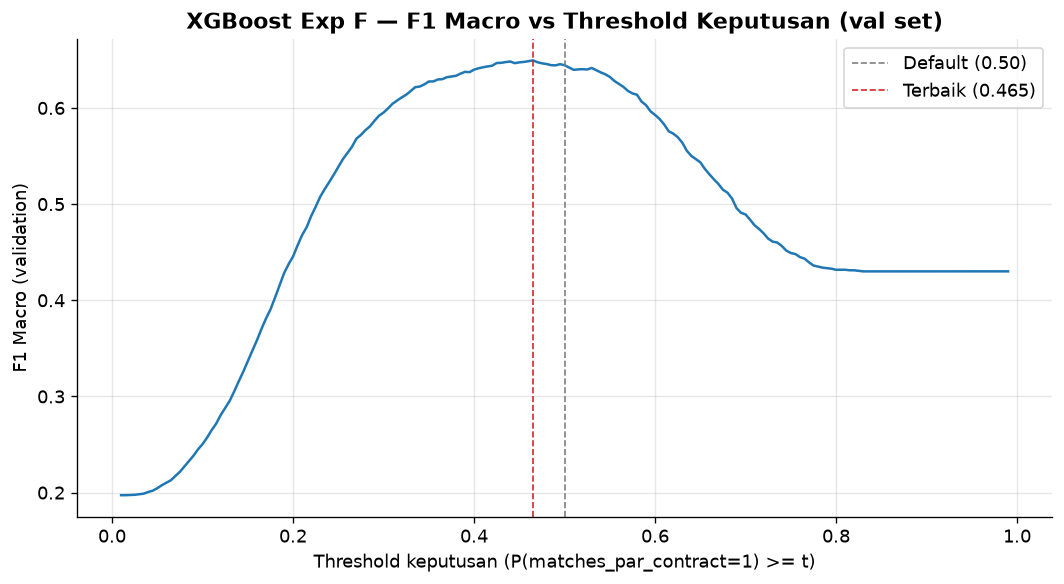

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, f1_macro_by_threshold, color='tab:blue', linewidth=1.5)
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Default (0.50)')
ax.axvline(best_threshold, color='tab:red', linestyle='--', linewidth=1,
           label=f'Terbaik ({best_threshold:.3f})')
ax.set_xlabel('Threshold keputusan (P(matches_par_contract=1) >= t)')
ax.set_ylabel('F1 Macro (validation)')
ax.set_title('XGBoost Exp F — F1 Macro vs Threshold Keputusan (val set)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'nb06_threshold_tuning.png', bbox_inches='tight')
plt.show()


In [34]:
y_pred_thresh_val = (y_proba_f[:, 1] >= best_threshold).astype(int)
res_thresh = evaluate(y_val, y_pred_thresh_val, y_proba_f, le,
                       model_name=f'XGBoost (Exp F + threshold={best_threshold:.3f})')
print_summary(res_thresh)

print(f'\nDibanding Eksperimen F (threshold default 0.5):')
print(f'  Accuracy : {res_f["accuracy"]:.4f} -> {res_thresh["accuracy"]:.4f}'
      f'  ({(res_thresh["accuracy"]-res_f["accuracy"])*100:+.2f}pp)')
print(f'  F1 Macro : {res_f["f1_macro"]:.4f} -> {res_thresh["f1_macro"]:.4f}'
      f'  ({(res_thresh["f1_macro"]-res_f["f1_macro"])*100:+.2f}pp)')



  XGBoost (Exp F + threshold=0.465)
  Accuracy          : 0.7429
  Precision (macro) : 0.6511
  Recall (macro)    : 0.6478
  F1 (macro)        : 0.6494
  F1 (weighted)     : 0.7415
  F1 (positive)     : 0.4683
  ROC-AUC           : 0.7142
  PR-AUC (avg prec) : 0.4665

Dibanding Eksperimen F (threshold default 0.5):
  Accuracy : 0.7550 -> 0.7429  (-1.21pp)
  F1 Macro : 0.6443 -> 0.6494  (+0.50pp)


## 8. Perbandingan Val Set — Semua Kandidat


In [35]:
from src.evaluation import compare_models

all_val_results = [
    baseline_results['RandomForest'], baseline_results['XGBoost'], baseline_results['LightGBM'],
    res_a, res_b, res_c, res_e, res_f, res_thresh,
]
val_comparison = compare_models(all_val_results)
val_comparison.to_csv(OUT / 'nb06_val_comparison.csv')
print(f'=== Perbandingan Validation Set — Baseline vs Eksperimen ({n_features} fitur, matches_par_contract) ===')
display(val_comparison.style
    .format('{:.4f}')
    .highlight_max(color='#C8E6C9', axis=0)
    .set_caption('Hijau = nilai terbaik per metrik'))


=== Perbandingan Validation Set — Baseline vs Eksperimen (164 fitur, matches_par_contract) ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_positive,roc_auc,average_precision
model,,,,,,,,
RandomForest,0.7653,0.6711,0.6170,0.6295,0.7436,0.4051,0.7148,0.4704
XGBoost,0.7712,0.6994,0.5729,0.5731,0.7210,0.2823,0.7115,0.4665
LightGBM,0.7213,0.6373,0.6509,0.6425,0.7279,0.4747,0.7126,0.4590
XGBoost (Exp A: retuned),0.7712,0.6994,0.5729,0.5731,0.7210,0.2823,0.7115,0.4665
XGBoost (Exp B: retuned+balanced),0.7084,0.6330,0.6553,0.6393,0.7196,0.4815,0.7113,0.4611
LightGBM (Exp C: retuned+balanced),0.7335,0.6417,0.6434,0.6425,0.7342,0.4622,0.7126,0.4632
RandomForest (Exp E: retuned),0.7664,0.6733,0.6195,0.6323,0.7452,0.4102,0.7175,0.4742
XGBoost (Exp F: soft-balanced alpha=0.5),0.7550,0.6593,0.6358,0.6443,0.7452,0.4460,0.7142,0.4665
XGBoost (Exp F + threshold=0.465),0.7429,0.6511,0.6478,0.6494,0.7415,0.4683,0.7142,0.4665


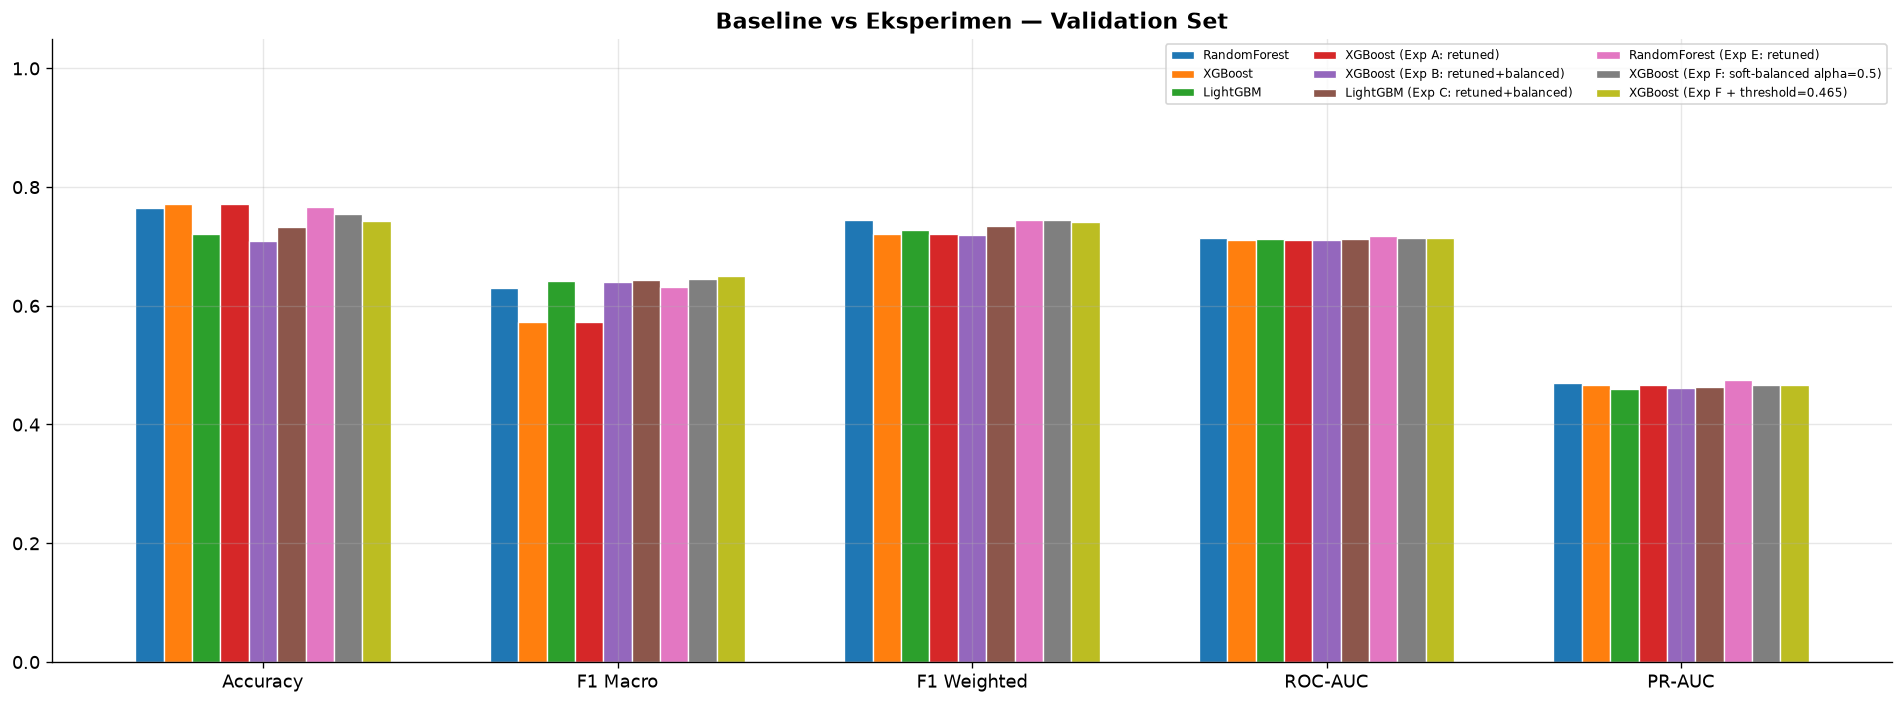

In [36]:
fig, ax = plt.subplots(figsize=(16, 6))
metrics_plot  = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision']
metrics_label = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'ROC-AUC', 'PR-AUC']
x = np.arange(len(metrics_plot))
w = 0.08
colors_all = sns.color_palette('tab10', len(all_val_results))

for i, (res, color) in enumerate(zip(all_val_results, colors_all)):
    vals = [res.get(m, 0) for m in metrics_plot]
    ax.bar(x + i * w, vals, w, label=res['model'], color=color, edgecolor='white', linewidth=0.8)

ax.set_xticks(x + w * (len(all_val_results) - 1) / 2)
ax.set_xticklabels(metrics_label, fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_title('Baseline vs Eksperimen — Validation Set', fontsize=13, fontweight='bold')
ax.legend(fontsize=7, ncol=3)
plt.tight_layout()
plt.savefig(OUT / 'nb06_val_comparison.png', bbox_inches='tight')
plt.show()


## 9. Simpan Model Kandidat

Model kandidat Eksperimen A, B, C, E, F disimpan ke `outputs/models/` dengan
nama deskriptif (`*_expA_*.pkl`, dst.), pakai `joblib` (`compress=3`) supaya
file besar (RandomForest Exp E) tetap wajar ukurannya.

**Tidak menimpa** `outputs/models/{randomforest,xgboost,lightgbm}.pkl` (baseline dari `04_modeling.ipynb`). Model kandidat ini tidak termasuk perbandingan final enam baseline di Notebook 08.
Promosi ke pipeline resmi tetap keputusan terpisah (lihat kesimpulan di bawah).


In [37]:
import joblib
from src.models import XGBModel, LGBMModel, RFModel

def _save(obj, filename, compress=3):
    joblib.dump(obj, MODEL_DIR / filename, compress=compress)
    mb = (MODEL_DIR / filename).stat().st_size / 1e6
    print(f'  {filename:<40} {mb:>7,.1f} MB')

def _wrap(model_cls, params, fitted_clf):
    w = model_cls(**params)
    w.clf = fitted_clf
    return w

print('Menyimpan artefak kandidat eksperimen noDDS A/B/C/E/F ...')
_save(_wrap(RFModel,   best_rf_params,   rf_e),   'randomforest_expE_retuned.pkl')
_save(_wrap(XGBModel,  best_xgb_params,  xgb_a),  'xgboost_expA_default.pkl')
_save(_wrap(XGBModel,  best_xgb_params,  xgb_b),  'xgboost_expB_balanced.pkl')
_save(_wrap(XGBModel,  best_xgb_params,  xgb_f),  'xgboost_expF_softbalance.pkl')
_save(_wrap(LGBMModel, best_lgbm_params, lgbm_c), 'lightgbm_expC_retuned.pkl')

print('\n5 model kandidat tersimpan. Notebook 08 tetap membandingkan enam baseline DDS/noDDS yang berpasangan.')


Menyimpan artefak kandidat eksperimen noDDS A/B/C/E/F ...
  randomforest_expE_retuned.pkl               85.8 MB
  xgboost_expA_default.pkl                     0.4 MB
  xgboost_expB_balanced.pkl                    0.4 MB
  xgboost_expF_softbalance.pkl                 0.4 MB
  lightgbm_expC_retuned.pkl                    1.7 MB

5 model kandidat tersimpan. Notebook 08 tetap membandingkan enam baseline DDS/noDDS yang berpasangan.


## Ringkasan dan Tahap Berikutnya

Pemilihan kandidat dilakukan berdasarkan validation set. Pemilihan kandidat dan threshold hanya berdasarkan validation. Kandidat eksperimen ini tidak ikut menentukan hasil perbandingan baseline DDS/noDDS di Notebook 08.


In [38]:
_metric_keys = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision']
selected_val_ap = max(all_val_results, key=lambda r: r['average_precision'])
selected_val_f1 = max(all_val_results, key=lambda r: r['f1_macro'])
selected_val_acc = max(all_val_results, key=lambda r: r['accuracy'])
summary_nb06 = {
    'n_candidates_compared_on_validation': len(all_val_results),
    'primary_selection_metric': 'average_precision on validation set',
    'validation_results': {r['model']: {k: r[k] for k in _metric_keys} for r in all_val_results},
    'selected_by_validation_average_precision': selected_val_ap['model'],
    'selected_by_validation_f1_macro_secondary': selected_val_f1['model'],
    'selected_by_validation_accuracy_secondary': selected_val_acc['model'],
    'best_xgb_params_exp_a': best_xgb_params,
    'best_lgbm_params_exp_c': best_lgbm_params,
    'best_rf_params_exp_e': best_rf_params,
    'best_alpha_exp_f': best_alpha,
    'best_threshold_exp_f': best_threshold,
}
with open(OUT / 'nb06_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary_nb06, f, indent=2, ensure_ascii=False)

print('=' * 70)
print('  ANALISIS EKSPERIMEN — pemilihan kandidat hanya dari validation')
print('=' * 70)
print(f"Kandidat terbaik berdasarkan AP: {selected_val_ap['model']} ({selected_val_ap['average_precision']:.4f})")
print(f"F1 macro terbaik (sekunder): {selected_val_f1['model']} ({selected_val_f1['f1_macro']:.4f})")
print(f"Accuracy terbaik (sekunder): {selected_val_acc['model']} ({selected_val_acc['accuracy']:.4f})")
print('Skor test kandidat eksperimen tidak dihitung; evaluasi utama enam baseline dilaporkan di Notebook 08.')


  ANALISIS EKSPERIMEN — pemilihan kandidat hanya dari validation
Kandidat terbaik berdasarkan AP: RandomForest (Exp E: retuned) (0.4742)
F1 macro terbaik (sekunder): XGBoost (Exp F + threshold=0.465) (0.6494)
Accuracy terbaik (sekunder): XGBoost (0.7712)
Skor test kandidat eksperimen tidak dihitung; evaluasi utama enam baseline dilaporkan di Notebook 08.
